In [13]:
from langgraph.graph import StateGraph, START, END

In [14]:
from typing import TypedDict

from langgraph.graph import MessagesState


class State(TypedDict):
    task: str
    backend_done: bool
    frontend_done: bool
    qa_passed: bool
    qa_attempts: int
    qa_feedback: str
    next_agent: str

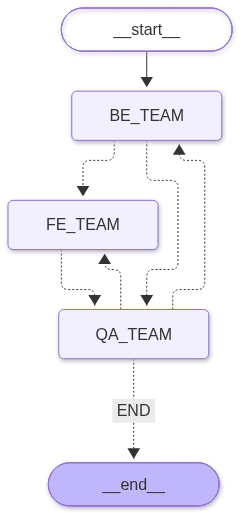

In [15]:

def BE_TEAM(state: State):

    print("Backend Agent executing...")

    if state["qa_feedback"]:
        print("Fixing issue:", state["qa_feedback"])

        return {
            "backend_done": True,
            "qa_feedback": "",
            "next_agent": "QA_TEAM"
        }

    print("Creating backend API...")

    return {
        "backend_done": True,
        "next_agent": "FE_TEAM"
    }


# 3. Frontend agent
def FE_TEAM(state: State):

    if  state['qa_feedback']:
        print("fixinf issues", state["qa_feedback"])

        return {
            "frontend_done": True,
            "qa_feedback": "",
            "next_agent": "QA_TEAM"
        }


    print("Frontend Agent executing...")
    print("Integrating backend API...")

    return {
        "frontend_done": True,
        "next_agent": "QA_TEAM"
    }


# 4. QA agent
def QA_TEAM(state: State):

    print("QA Agent executing...")

    attempts = state["qa_attempts"] + 1

    # Simulate: first test fails, second test passes
    if attempts == 1:
        print("QA found a backend issue")

        return {
            "qa_attempts": attempts,
            "qa_passed": False,
            "qa_feedback": "API returns incorrect response",
            "next_agent": "BE_TEAM"
        }
    if attempts == 2:
        print("QA found a fe issue")

        return {
            "qa_attempts": attempts,
            "qa_passed": False,
            "qa_feedback": "FE is not responsive",
            "next_agent": "FE_TEAM"
        }

    print("All tests passed!")

    return {
        "qa_attempts": attempts,
        "qa_passed": True,
        "next_agent": "END"
    }


# 5. Conditional routing
def route_agent(state: State):
    return state["next_agent"]


# 6. Build graph
graph = StateGraph(State)

graph.add_node("BE_TEAM", BE_TEAM)
graph.add_node("FE_TEAM", FE_TEAM)
graph.add_node("QA_TEAM", QA_TEAM)

graph.add_edge(START, "BE_TEAM")

graph.add_conditional_edges(
    "BE_TEAM",
    route_agent,
    {
        "FE_TEAM": "FE_TEAM",
        "QA_TEAM": "QA_TEAM"
    }
)

graph.add_conditional_edges(
    "FE_TEAM",
    route_agent,
    {
        "QA_TEAM": "QA_TEAM"
    }
)

graph.add_conditional_edges(
    "QA_TEAM",
    route_agent,
    {
        "BE_TEAM": "BE_TEAM",
        "FE_TEAM": "FE_TEAM",
        "END": END
    }
)
graph.compile()



In [17]:
workflow = graph.compile()


# 7. Execute
result = workflow.invoke({
    "task": "Build prep assignment feature",
    "backend_done": False,
    "frontend_done": False,
    "qa_passed": False,
    "qa_attempts": 0,
    "qa_feedback": "",
    "next_agent": ""
})

print(result)

Backend Agent executing...
Creating backend API...
Frontend Agent executing...
Integrating backend API...
QA Agent executing...
QA found a backend issue
Backend Agent executing...
Fixing issue: API returns incorrect response
QA Agent executing...
QA found a fe issue
fixinf issues FE is not responsive
QA Agent executing...
All tests passed!
{'task': 'Build prep assignment feature', 'backend_done': True, 'frontend_done': True, 'qa_passed': True, 'qa_attempts': 3, 'qa_feedback': '', 'next_agent': 'END'}
